# siglip2_probe:SigLIP2 版 3DRAE 与 DINOv2 版的 probe 对比

**问题**:把 3DRAE 的图像编码器从 DINOv2 换成语言对齐的 SigLIP2(`configs/models/siglip2_feature.yaml`,官方权重),token 是否更容易按名字查询。

**做法**:与 `jepa3d/geo_probe` 的 DINOv2 版完全相同的 probe、数据和训练计划(EmbodiedScan ScanNet,训练 913 / 验证 229 个场景,100 个 epoch,种子 0),只换 `--feature-config`。任务 13005–13008。

| probe | 输入 → 输出 | 测什么 |
|---|---|---|
| 类别→位置 | 类别名 → 3D 位置 | 名字能否对到 token |
| 点提示→位置 | 一张图上的一个点 → 3D 位置 | token 里的几何 |
| 射线→类别(注意力) | 一条射线 → 类别 | token 里的语义能否按位置读出 |
| 射线→类别(patch 索引) | 射线所在的 2D patch → 类别 | 编码器 2D patch 本身的语义,不经过 3DRAE 的 neck |

结果文件在 `../results/{siglip2,dinov2}_*`(DINOv2 的是从 `outputs/geo_probe` 复制的)。

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt

def final(name):
    return json.load(open(f"../results/{name}/final_metrics.json"))

def curve(name, key):
    rows = [json.loads(line) for line in open(f"../results/{name}/metrics.jsonl")]
    return [(r["epoch"], r["val"][key]["value"]) for r in rows if "val" in r]

def fmt(v, pct=False):
    k = 100 if pct else 1
    unit = "%" if pct else ""
    digits = 1 if pct else 2
    return f'{k * v["value"]:.{digits}f}{unit} [{k * v["ci95"][0]:.{digits}f}, {k * v["ci95"][1]:.{digits}f}]'

## 1. 位置 probe(可见物体,验证集)

「打乱」= 评估时把 token 换成别的场景的,用来看 probe 用了多少场景信息。方括号是按场景重采样的 95% 置信区间。

In [2]:
rows = []
for probe, label in (("category", "类别→位置"), ("point", "点提示→位置")):
    for enc in ("dinov2", "siglip2"):
        f = final(f"{enc}_{probe}")
        rows.append({"probe": label, "编码器": enc,
                     "位置误差中位数 (m)": fmt(f["eval_real"]["visible/position_m"]),
                     "象限准确率": fmt(f["eval_real"]["visible/quadrant_acc"], True),
                     "打乱 token 后的位置误差 (m)": fmt(f["eval_shuffled"]["visible/position_m"])})
pd.DataFrame(rows)

,probe,编码器,位置误差中位数 (m),象限准确率,打乱 token 后的位置误差 (m)
0,类别→位置,dinov2,"0.95 [0.86, 1.05]","45.6% [43.3, 48.9]","2.10 [1.95, 2.26]"
1,类别→位置,siglip2,"1.07 [0.97, 1.17]","42.9% [40.5, 45.2]","2.11 [1.95, 2.29]"
2,点提示→位置,dinov2,"0.27 [0.25, 0.29]","84.3% [82.8, 85.5]","1.16 [1.06, 1.25]"
3,点提示→位置,siglip2,"0.24 [0.23, 0.26]","83.2% [81.6, 84.7]","0.96 [0.87, 1.05]"


## 2. 射线→类别(验证集,195 类,猜最多的类是 4.5%)

In [3]:
rows = []
for probe, label in (("reverse", "注意力读 3DRAE token"), ("reverse_index", "直接取编码器的 2D patch")):
    for enc in ("dinov2", "siglip2"):
        f = final(f"{enc}_{probe}")
        row = {"读法": label, "编码器": enc, "top-1": fmt(f["eval_real"]["top1"], True),
               "top-5": fmt(f["eval_real"]["top5"], True), "按类平均 top-1": f'{100 * f["eval_real"]["macro_top1"]:.1f}%'}
        row["打乱 token 后 top-1"] = fmt(f["eval_shuffled"]["top1"], True) if "eval_shuffled" in f else "—"
        rows.append(row)
pd.DataFrame(rows)

,读法,编码器,top-1,top-5,按类平均 top-1,打乱 token 后 top-1
0,注意力读 3DRAE token,dinov2,"31.8% [29.1, 34.6]","58.8% [55.5, 62.3]",16.1%,"8.0% [6.3, 9.9]"
1,注意力读 3DRAE token,siglip2,"30.1% [27.6, 32.5]","57.9% [54.9, 61.2]",14.7%,"7.7% [6.0, 9.5]"
2,直接取编码器的 2D patch,dinov2,"56.4% [53.7, 59.0]","78.6% [76.2, 81.1]",40.7%,—
3,直接取编码器的 2D patch,siglip2,"38.7% [36.4, 41.2]","64.9% [61.9, 67.9]",25.5%,—


## 3. 训练过程中的验证误差

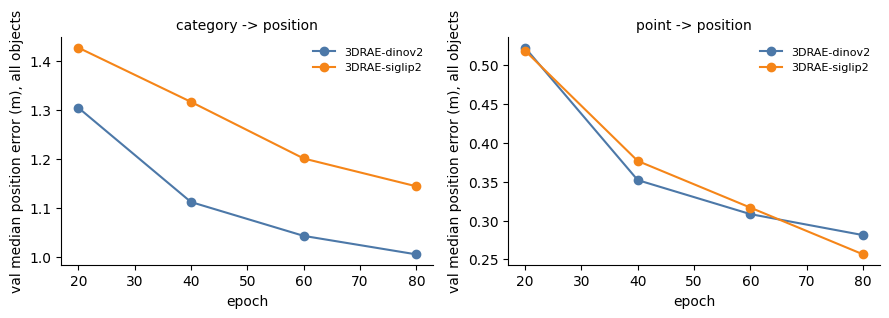

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, (probe, title) in zip(axes, (("category", "category -> position"), ("point", "point -> position"))):
    for enc, color in (("dinov2", "#4c78a8"), ("siglip2", "#f58518")):
        c = curve(f"{enc}_{probe}", "all/position_m")
        ax.plot([e for e, _ in c], [v for _, v in c], "o-", color=color, label=f"3DRAE-{enc}")
    ax.set_title(title, fontsize=10); ax.set_xlabel("epoch"); ax.set_ylabel("val median position error (m), all objects")
    ax.legend(frameon=False, fontsize=8); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 4. 结论

1. **换成 SigLIP2 没有改善名字定位。** 类别→位置:SigLIP2 版 1.07 m / 42.9%,DINOv2 版 0.95 m / 45.6%。SigLIP2 略差,置信区间重叠,不能说有差别,但肯定没有变好。
2. **几何没有变差。** 点提示→位置:SigLIP2 版 0.24 m,DINOv2 版 0.27 m,区间略有重叠。
3. **按位置读类别,两者一样。** 注意力读法 30.1% 对 31.8%。
4. **SigLIP2 的 2D patch 语义反而弱得多。** patch 索引读法 38.7% 对 DINOv2 的 56.4%,区间不重叠。一个可能的解释是 SigLIP2 的语言对齐主要在整图特征上,这里没有验证。
5. **所以不建议换编码器。** 「编码器是否语言对齐」不是名字定位差的原因;两个版本都卡在同一个水平,训练误差都降到 0.08 m 而验证误差在 1 m 左右,仍然是过拟合,即监督量的问题。

## 5. 局限

- 每个配置只跑了一个种子。类别→位置上 0.1 m 的差距在区间之内,不要解读成 SigLIP2 更差。
- probe 的文本端是 probe 自己学的类别嵌入,没有用 SigLIP2 的文本塔。所以这里测的是「token 好不好学」,没有测 SigLIP2 的零样本图文对齐。
- SigLIP2 是 patch 16、输入 256,进 neck 前按官方做法缩放到 14 的网格;没有试别的分辨率。